In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import auc, precision_score, recall_score, f1_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold

In [4]:
df = pd.read_csv('course_lead_scoring_2026.csv')

### Question 1: ROC AUC feature importance

In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [7]:
target = 'converted'
categorical = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
numerical = [c for c in df.columns if c not in categorical and c != target]
print('categorical:', categorical)
print('numerical:', numerical)

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
df.isnull().sum().sum

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

len(df_train), len(df_val), len(df_test)

categorical: ['lead_source', 'industry', 'employment_status', 'location']
numerical: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


(3000, 1000, 1000)

In [8]:
q1_vars = ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']
for col in q1_vars:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f'{col:28s} {auc:.4f}')

lead_score                   0.7882
number_of_courses_viewed     0.7230
interaction_count            0.7649
annual_income                0.6082


### Question 2: Training the model

In [10]:
features = categorical + numerical

def train(df_, y_, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_)
    return dv, model

def predict(df_, dv, model):
    X = dv.transform(df_[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
auc = roc_auc_score(y_val, y_pred)
print('Validation AUC:', round(auc, 3))

Validation AUC: 0.732


### Question 3: Precision and Recall

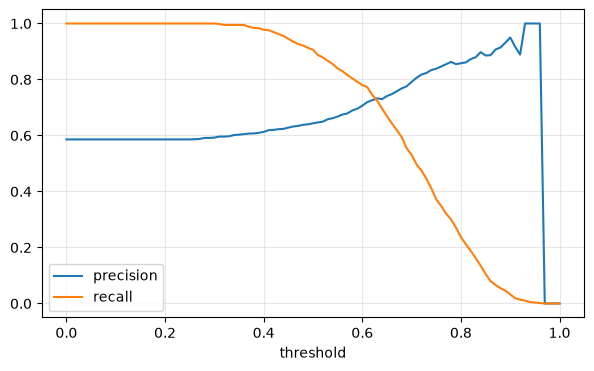

In [12]:
thresholds = np.round(np.arange(0.0, 1.01, 0.01), 2)
rows = []
for t in thresholds:
    pred_pos = y_pred >= t
    actual_pos = y_val == 1
    tp = (pred_pos & actual_pos).sum()
    fp = (pred_pos & ~actual_pos).sum()
    fn = (~pred_pos & actual_pos).sum()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    rows.append((t, tp, fp, fn, p, r))

df_scores = pd.DataFrame(rows, columns=['threshold', 'tp', 'fp', 'fn', 'precision', 'recall'])

plt.figure(figsize=(7, 4))
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [13]:
valid = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
valid['diff'] = (valid.precision - valid.recall).abs()
best = valid.sort_values('diff').iloc[0]
print('Intersection threshold:', best.threshold)
valid.sort_values('diff').head(5)

Intersection threshold: 0.63


,threshold,tp,fp,fn,precision,recall,diff
63,0.63,425,155,161,0.732759,0.725256,0.007503
62,0.62,437,165,149,0.725914,0.745734,0.019820
64,0.64,408,151,178,0.729875,0.696246,0.033629
61,0.61,453,177,133,0.719048,0.773038,0.053990
65,0.65,392,137,194,0.741021,0.668942,0.072079


### Question 4: F1 score

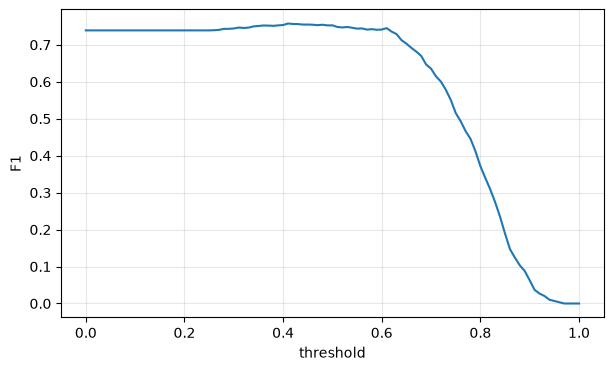

Max F1 threshold: 0.41  F1 = 0.7576


In [14]:
df_scores['f1'] = np.where(
    (df_scores.precision + df_scores.recall) > 0,
    2 * df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall),
    0.0,
)

plt.figure(figsize=(7, 4))
plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('threshold'); plt.ylabel('F1'); plt.grid(alpha=0.3)
plt.show()

best_f1 = df_scores.loc[df_scores.f1.idxmax()]
print('Max F1 threshold:', best_f1.threshold, ' F1 =', round(best_f1.f1, 4))

### Question 5: 5-Fold CV

In [16]:
def cv_scores(C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        dv_, model_ = train(df_tr, df_tr[target].values, C=C)
        y_p = predict(df_va, dv_, model_)
        scores.append(roc_auc_score(df_va[target].values, y_p))
    return np.array(scores)

scores = cv_scores(1.0)
print('Fold AUCs:', np.round(scores, 4))
print(f'mean = {scores.mean():.3f}, std = {scores.std():.3f}')

Fold AUCs: [0.7306 0.7296 0.7363 0.7412 0.7209]
mean = 0.732, std = 0.007


### Question 6: Hyperparameter Tuning

In [18]:
results = []
for C in [0.000001, 0.001, 1]:
    s = cv_scores(C)
    results.append((C, round(s.mean(), 3), round(s.std(), 3)))
    print(f'C={C:<10} mean={s.mean():.3f}  std={s.std():.3f}')

res = pd.DataFrame(results, columns=['C', 'mean', 'std'])
best_C = res.sort_values(['mean', 'std', 'C'], ascending=[False, True, True]).iloc[0].C
print('Best C:', best_C)

C=1e-06      mean=0.617  std=0.019
C=0.001      mean=0.749  std=0.010
C=1          mean=0.732  std=0.007
Best C: 0.001
